# Quadratic inference with a fill-fraction objective (4D) in the scattered-voltage basis

Extension of `quadraticInferenceParetoVoltage.ipynb`. The objective of each continuation step is no longer the inference error alone, but
the weighted combination

$$F(x) = (1-w)\,\frac{J_\mathrm{inf}(x)}{J_\mathrm{inf}(x_\mathrm{opt})} + w\,D(x), \qquad D(x) = \left|\frac{1}{N}\sum_i \varsigma_i(x) - \rho\right|^2, \qquad w \in [0, 1],$$

where $\varsigma_i(x) = Z_s I_i/(V + V_\mathrm{sca})_i$, $I = -Wx$, is the inferred material density in the voltage basis
(Sec. *Total-Voltage Formulation* and Eq. *inferredDensity* of `main.tex`). $D$ penalizes the deviation of the mean density from $\rho$
; since $\varsigma$ is complex, it also penalizes the imaginary part of the mean density. Both terms are
replaced by their local second-order expansions at the current expansion point, and the step

$$\min_d \tilde F^{(k)}(d)\quad \text{s.t.}\quad (x-x_\mathrm{opt})^H L^\star (x-x_\mathrm{opt}) = \varepsilon,\qquad P(x) = P_\mathrm{target},\qquad x = x_k + d,$$

is solved with the Hermitian Takagi upper model as a `DenseSharedProjQCQP` with two general constraints. The result is a 4D front over
$(\varepsilon, P_\mathrm{target})$ with the two objectives $J_\mathrm{inf}$ and $D$, for each weight $w$ in `WEIGHTS` (target density `RHO`).

In [23]:
import numpy as np
import scipy.sparse as sp
import scipy.linalg as sla
import time
import copy
import warnings
import matplotlib.pyplot as plt
from IPython.display import display
from dolphindes.cvxopt import DenseSharedProjQCQP, OptimizationHyperparameters
from dolphindes.cvxopt.gcd import GCDHyperparameters

In [24]:
# Physical constants
epsilon_0 = 8.854e-12 # F/m
mu_0 = 4e-7 * np.pi # H/m
c = 1/np.sqrt(epsilon_0 * mu_0) # speed of light in vacuum

E0 = 1e3 # plane wave amplitude in V/m

frequency = 2.45e9 # frequency in Hz
wavelength = c / frequency # wavelength in m
print(f"Wavelength: {wavelength} m")

ka = 1 # electrical size of the antenna
k = 2 * np.pi / wavelength # wavenumber
a = ka / k # antenna circumradius
print(f"Antenna circumradius: {a} m")

omega = 2 * np.pi * frequency # angular frequency

conductivity_reduction_factor = 1 # factor to reduce conductivity for testing purposes
copper_conductivity = conductivity_reduction_factor*5.96e7 # S/m
copper_permittivity = 1 + 1j * copper_conductivity / (omega * epsilon_0) # copper permittivity in dimensionless units
print(f"Copper permittivity: {copper_permittivity:.2e}")

Wavelength: 0.1223655664053944 m
Antenna circumradius: 0.019475084757658086 m
Copper permittivity: 1.00e+00+4.37e+08j


In [25]:
# Calculate surface impedance
delta = np.sqrt(2 / (omega * mu_0 * copper_conductivity)) # skin depth in m
Zs = (1 + 1j) / (copper_conductivity * delta)
print(f"Surface impedance: {Zs} Ω")

# Load matrices from text files
# Lmat = np.loadtxt(r"Lmat_dipole.txt", delimiter=',') # lossy matrix
Lmat = np.loadtxt(r"Lmat_patch21ka1.txt", delimiter=',') # lossy matrix


Ndes = Lmat.shape[0] # number of design variables
print("Number of design variables: ", Ndes)

Lchol = np.linalg.cholesky(Lmat).conj().T
LcholInv = np.linalg.inv(Lchol)

def Msym(M):
    return(0.5*(M.conj().T + M))

def Mchol(M):
    return(Msym(LcholInv.conj().T @ M @ LcholInv))

# R0 = np.loadtxt(r"R0_dipole.txt", delimiter=',') # radiated power matrix
R0 = np.loadtxt(r"R0_patch21ka1.txt", delimiter=',') # radiated power matrix
R0 = Mchol(R0)

# X0 = np.loadtxt(r"X0_dipole.txt", delimiter=',') # reactive power matrix
X0 = np.loadtxt(r"X0_patch21ka1.txt", delimiter=',') # reactive power matrix
X0 = Mchol(X0)

# Vinc = np.loadtxt(r"V_dipole.txt", delimiter=',') # voltage excitation vector
Vinc = np.loadtxt(r"V_patch21ka1.txt", delimiter=',') # voltage excitation vector
Vinc = E0*Vinc
def Vchol(v):
    return(LcholInv.conj().T @ v)
Vinc = Vchol(Vinc)

Zmat = Zs * np.eye(Ndes) # material impedance matrix
Z0 = R0 + 1j*X0 # free-space impedance matrix
Ztot = Z0 + Zmat # total impedance matrix

def evalObjI(Ivec):
    # radiated power in the current basis
    return(0.5*np.real(Ivec.conj().T @ R0 @ Ivec))

# full plate performance
Ifull = np.linalg.solve(Ztot, Vinc) # current distribution for full plate
Pfull = evalObjI(Ifull) # objective for full plate
print(f"Objective for full plate: {Pfull:.6e} W")

Surface impedance: (0.012739130327240646+0.012739130327240646j) Ω
Number of design variables:  233
Objective for full plate: 4.114174e-02 W


## Objective and power conservation in $V_\mathrm{sca}$

With $I = -W V_\mathrm{sca}$, $W = Z_0^{-1}$, the radiated power is $-x^H A_0 x$ with $A_0 = -\tfrac12 W^H R_0 W$, and the power conservation
constraints take the shared projector form with $A_1 = 1 + Z_s^* W^H$, $A_2 = W$, $s_1 = -\tfrac12 V$ (derivation in `VscatBound.ipynb`).

In [26]:
print(f"cond(Z0) = {np.linalg.cond(Z0):.3e}")
W = np.linalg.inv(Z0)   # Z0^{-1}
WH = W.conj().T

Obj = -0.5 * Msym(WH @ R0 @ W)
obj = np.zeros(Ndes, dtype=complex)
obj0 = 0.0

def VtoI(Vsca):
    return(-W @ Vsca)

def evalObj(Vsca):
    return(-np.real(Vsca.conj().T @ Obj @ Vsca) + 2*np.real(Vsca.conj().T @ obj) + obj0)

Vfull = -Z0 @ Ifull # scattered voltage for full plate
print(f"Objective for full plate in Vsca: {evalObj(Vfull):.6e} W (I basis {Pfull:.6e} W)")

cond(Z0) = 1.174e+03
Objective for full plate in Vsca: 4.114174e-02 W (I basis 4.114174e-02 W)


In [27]:
A1 = np.eye(Ndes) + np.conj(Zs) * WH
A2 = W
s1 = -0.5 * Vinc

qList = [1, -1j]   # real and imaginary part (real and reactive power), p = q 1
Plist = [sp.diags(np.conj(q)*np.ones(Ndes, dtype=complex)) for q in qList]   # P' = diag(p^*)

def projRes(x, Pp):
    # Re(-x^H A1 P' A2 x + 2 x^H A2^H P'^H s1)
    return(np.real(-x.conj() @ A1 @ (Pp @ (A2 @ x)) + 2*x.conj() @ (A2.conj().T @ (Pp.conj().T @ s1))))

def directRes(Vsca, p):
    # Re[I^H diag(p) (V + Vsca - Zs I)] evaluated directly
    I = VtoI(Vsca)
    return(np.real(np.sum(p*np.conj(I)*(Vinc + Vsca - Zs*I))))

print("power conservation residuals at full plate:",
      [f"{projRes(Vfull, Pp):.2e} (direct {directRes(Vfull, q*np.ones(Ndes)):.2e})" for Pp, q in zip(Plist, qList)])

# check: shared projector form equals the direct constraint for a random projector at a random point
pRand = np.random.randn(Ndes) + 1j*np.random.randn(Ndes)
xRand = np.random.randn(Ndes) + 1j*np.random.randn(Ndes)
print(f"random p, random x: shared form {projRes(xRand, sp.diags(np.conj(pRand))):.6e}, direct {directRes(xRand, pRand):.6e}")

power conservation residuals at full plate: ['2.78e-17 (direct 1.78e-17)', '2.22e-16 (direct -6.59e-16)']
random p, random x: shared form 5.421001e+00, direct 5.421001e+00


## Global bound

In [28]:
QCQP = DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, Plist, A2=A2, verbose=1)

lags_init = np.array([1.0, 0.0])   # lambda = 1 on the real power constraint
print(f"initial lags dual feasible: {QCQP.is_dual_feasible(lags_init)}")

opt_params = OptimizationHyperparameters(opttol=1e-6,
    gradConverge=True,
    min_inner_iter=10,
    max_restart=10,
    penalty_ratio=1e-2,
    penalty_reduction=0.1,
    break_iter_period=5,
    verbose=0)

t1 = time.time()
result = QCQP.solve_current_dual_problem(method='newton', init_lags=lags_init, opt_params=opt_params)
print(f"bound: {result[0]:.6e} W, time: {time.time()-t1:.2f}s, Lagrange multipliers: {QCQP.current_lags}")

lags = QCQP.current_lags
totalA = QCQP._get_total_A(lags)
print(f"minimum eigenvalue of A: {np.min(np.linalg.eigvalsh(Msym(totalA))):.3e}")

Vstar = QCQP.current_xstar
Istar = VtoI(Vstar)
print(f"dual bound {QCQP.current_dual:.6e} W, P(x*) {evalObj(Vstar):.6e} W (I basis {evalObjI(Istar):.6e} W), full plate {Pfull:.6e} W")
print("constraint residuals at x*:", [f"{projRes(Vstar, Pp):.2e}" for Pp in Plist])

Precomputed 2 A matrices and Fs vectors.
initial lags dual feasible: True
bound: 1.847944e+01 W, time: 0.10s, Lagrange multipliers: [ 8.83797872e-01 -4.10993839e-05]
minimum eigenvalue of A: 6.851e-09
dual bound 1.847944e+01 W, P(x*) 1.847944e+01 W (I basis 1.847944e+01 W), full plate 4.114174e-02 W
constraint residuals at x*: ['-4.25e-07', '4.11e-03']


## Local projector constraints by GCD

In [29]:
Ngcd = 40   # number of GCD iterations, each adds a max violation and a min eigenvalue projector

gQCQP = copy.deepcopy(QCQP)
gQCQP.verbose = 0
gcd_params = GCDHyperparameters(max_proj_cstrt_num=2 + 2*Ngcd,
    max_gcd_iter_num=Ngcd,
    gcd_iter_period=Ngcd + 1,   # no early termination
    opt_params=opt_params)

t1 = time.time()
gQCQP.run_gcd(gcd_params)
print(f"bound: {QCQP.current_dual:.6e} -> {gQCQP.current_dual:.6e} W (full plate {Pfull:.6e} W), "
      f"{gQCQP.n_proj_constr} projectors, {time.time()-t1:.2f}s")

At GCD iteration #1, best dual bound found is             18.479439958269776.
min eigenvalue: 6.851360e-09
At GCD iteration #2, best dual bound found is             18.331563384032123.
min eigenvalue: 5.900530e-09
At GCD iteration #3, best dual bound found is             18.21958288423426.
min eigenvalue: 3.891572e-09
At GCD iteration #4, best dual bound found is             18.116345305475132.
min eigenvalue: 1.260090e-09
At GCD iteration #5, best dual bound found is             18.058141937962507.
min eigenvalue: 3.000890e-10
At GCD iteration #6, best dual bound found is             18.01487446279795.
min eigenvalue: 4.903142e-11
At GCD iteration #7, best dual bound found is             17.996930004157047.
min eigenvalue: 3.607549e-10
At GCD iteration #8, best dual bound found is             17.97685936727628.
min eigenvalue: 3.898592e-13
At GCD iteration #9, best dual bound found is             17.966619899910352.
min eigenvalue: 3.122762e-14
At GCD iteration #10, best dual bound fo

In [30]:
# finetune the GCD multipliers with BFGS and check PSD-ness of A
t1 = time.time()
gcd_final_result = gQCQP.solve_current_dual_problem(method='bfgs', init_lags=gQCQP.current_lags, opt_params=None)
print(f"bound: {gcd_final_result[0]:.6e} W, time: {time.time()-t1:.2f}s")

print(f"min eigenvalue of A: {np.min(np.linalg.eigvalsh(Msym(gQCQP._get_total_A(gQCQP.current_lags)))):.3e}")
Vstar = gQCQP.current_xstar
print(f"GCD primal objective: {evalObj(Vstar):.6e} W, GCD dual bound: {gQCQP.current_dual:.6e} W")

bound: 1.761971e+01 W, time: 0.97s
min eigenvalue of A: 1.190e-13
GCD primal objective: 1.761793e+01 W, GCD dual bound: 1.761971e+01 W


## Quadratic inference model in $V_\mathrm{sca}$

The inference error $J_\mathrm{inf} = \sum_i |a_i b_i^*|^2$ uses the vacuum residual $a = Z_s I$ and the material residual
$b = (Z_s + Z_0) I - V$. With $I = -W x$ both are affine in $x$,
$$a = M_a x,\quad M_a = -Z_s W, \qquad b = M_b x - V,\quad M_b = -(1 + Z_s W),$$
and the second order expansion $J_\mathrm{inf}(x+d) \approx J_0 + 2\operatorname{Re}(g^H d) + d^H H d + \operatorname{Re}(d^T K d)$ has
$$g = M_a^H (|b|^2 a) + M_b^H (|a|^2 b),$$
$$H = M_a^H \operatorname{diag}|b|^2 M_a + M_b^H \operatorname{diag}|a|^2 M_b + M_a^H \operatorname{diag}(q) M_b + M_b^H \operatorname{diag}(q^*) M_a,\quad q = a b^*,$$
$$K = 2 M_a^T \operatorname{diag}(a^* b^*) M_b .$$
For the current basis ($M_a = Z_s$, $M_b = Z_s + Z_0$) this reduces to the expansion of `quadraticInferencePareto.ipynb`.

In [31]:
Vopt = gQCQP.current_xstar
Lstar = Msym(gQCQP._get_total_A(gQCQP.current_lags))   # quadratic part of the Lagrangian (Vsca basis)
lamMinL = np.min(np.linalg.eigvalsh(Lstar))
print(f"min eig L*: {lamMinL:.3e}")

Vzero = np.zeros(Ndes, dtype=complex)
Ma = -Zs*W                        # a = Zs I = Ma x
Mb = -(np.eye(Ndes) + Zs*W)       # b = (Zs + Z0) I - V = Mb x - V

def residuals(x):
    return Ma @ x, Mb @ x - Vinc          # vacuum residual a, material residual b

def Jinf(x):
    a, b = residuals(x)
    return np.sum(np.abs(a*b.conj())**2)

def inferredDensity(x):
    a, b = residuals(x)
    return a/(a - b)                        # = Zs I / (V + Vsca)

def taylor(x):
    """g, H, K of the second-order expansion of Jinf at x."""
    a, b = residuals(x)
    q = a*b.conj()
    Da, Db = np.abs(a)**2, np.abs(b)**2
    g = Ma.conj().T @ (Db*a) + Mb.conj().T @ (Da*b)
    H = (Ma.conj().T @ (Db[:, None]*Ma) + Mb.conj().T @ (Da[:, None]*Mb)
         + Mb.conj().T @ (q.conj()[:, None]*Ma) + Ma.conj().T @ (q[:, None]*Mb))
    K = 2*Ma.T @ (np.conj(a*b)[:, None]*Mb)
    return g, Msym(H), 0.5*(K + K.T)

def quadModel(F0, gHK, d):
    """F0 + 2Re[g^H d] + d^H H d + Re[d^T K d]"""
    g, H, K = gHK
    return F0 + 2*np.real(g.conj() @ d) + np.real(d.conj() @ H @ d) + np.real(d @ K @ d)

# sanity check of the expansion: error should scale as t^3
rng = np.random.default_rng(0)
dir_ = rng.standard_normal(Ndes) + 1j*rng.standard_normal(Ndes); dir_ *= np.linalg.norm(Vopt)/np.linalg.norm(dir_)
for t in [1e-2, 1e-3, 1e-4]:
    print(f"t={t:.0e}: |J - J~| / J = {abs(Jinf(Vopt + t*dir_) - quadModel(Jinf(Vopt), taylor(Vopt), t*dir_))/Jinf(Vopt):.3e}")
# consistency with the current basis: J_inf(x) = J_inf of I = -W x
Itest = VtoI(Vopt)
print(f"J_inf in Vsca basis {Jinf(Vopt):.6e}, in I basis {np.sum(np.abs(Zs*Itest*np.conj(Ztot @ Itest - Vinc))**2):.6e}")

min eig L*: 1.190e-13
t=1e-02: |J - J~| / J = 3.642e-05
t=1e-03: |J - J~| / J = 3.994e-08
t=1e-04: |J - J~| / J = 4.029e-11
J_inf in Vsca basis 1.960263e+03, in I basis 1.960263e+03


## Local quadratic model of the mean density deviation

The inferred density $\varsigma_i = a_i/u_i$, $a = M_a x$, $u = V + x$, is a holomorphic function of $x$ (no $x^*$ appears), and so is the mean
density $S(x) = \frac1N\sum_i \varsigma_i$. Its Taylor expansion $S(x + d) \approx S + c^T d + \tfrac12 d^T G d$ has
$$c_j = \frac1N\left(\sum_i \frac{M_{a,ij}}{u_i} - \frac{a_j}{u_j^2}\right), \qquad
G_{jk} = \frac1N\left(-\frac{M_{a,kj}}{u_k^2} - \frac{M_{a,jk}}{u_j^2} + 2\delta_{jk}\frac{a_j}{u_j^3}\right).$$
With $r = S - \rho$, the second-order expansion of $D = |S - \rho|^2$ is
$$\tilde D(d) = |r|^2 + 2\operatorname{Re}(g_D^H d) + d^H H_D d + \operatorname{Re}(d^T K_D d),\qquad g_D = r\,\bar c,\quad H_D = \bar c\, c^T,\quad K_D = \bar r\, G,$$
of the same form as the expansion of $J_\mathrm{inf}$. The combined model of $F$ is the convex combination, and its complex-symmetric part
$K = \frac{1-w}{J_\mathrm{ref}}K_J + w K_D$ is bounded by a single Takagi bound.

In [83]:
RHO = 0.5                 # target mean material density
WEIGHTS = [1-1e-9]           # w: F = (1-w) J_inf/J_ref + w D
Jref = Jinf(Vopt)         # normalization of the inference error
print(f"target density {RHO}, weights {WEIGHTS}, J_ref = {Jref:.3e}")

def meanDensity(x):
    return np.mean(inferredDensity(x))

def Dfill(x):
    return np.abs(meanDensity(x) - RHO)**2

def taylorFill(x):
    """g, H, K of the second-order expansion of D = |mean(rho(x)) - RHO|^2 at x."""
    a, u = Ma @ x, Vinc + x
    r = np.mean(a/u) - RHO
    c = (Ma.T @ (1/u) - a/u**2)/Ndes
    M1 = Ma/u[:, None]**2
    G = (-M1 - M1.T + np.diag(2*a/u**3))/Ndes
    return r*c.conj(), np.outer(c.conj(), c), np.conj(r)*G

def Ftot(x, w):
    return (1 - w)*Jinf(x)/Jref + w*Dfill(x)

def taylorTot(x, w):
    (g1, H1, K1), (g2, H2, K2) = taylor(x), taylorFill(x)
    s = (1 - w)/Jref
    K = s*K1 + w*K2
    return s*g1 + w*g2, Msym(s*H1 + w*H2), 0.5*(K + K.T)

print(f"mean density at x_opt: {meanDensity(Vopt):.4f}, D(x_opt) = {Dfill(Vopt):.3e}; full plate: {meanDensity(Vfull):.4f}")
# sanity check of the expansions: error should scale as t^3
for t in [1e-2, 1e-3, 1e-4]:
    d = t*dir_
    print(f"t={t:.0e}: |D - D~| / D = {abs(Dfill(Vopt + d) - quadModel(Dfill(Vopt), taylorFill(Vopt), d))/Dfill(Vopt):.3e}, "
          f"|F - F~| / F = {abs(Ftot(Vopt + d, WEIGHTS[0]) - quadModel(Ftot(Vopt, WEIGHTS[0]), taylorTot(Vopt, WEIGHTS[0]), d))/Ftot(Vopt, WEIGHTS[0]):.3e}")

target density 0.5, weights [0.999999999], J_ref = 1.960e+03
mean density at x_opt: 0.0000-0.0000j, D(x_opt) = 2.500e-01; full plate: 1.0000+0.0000j
t=1e-02: |D - D~| / D = 1.527e-05, |F - F~| / F = 1.527e-05
t=1e-03: |D - D~| / D = 2.287e-08, |F - F~| / F = 2.287e-08
t=1e-04: |D - D~| / D = 2.404e-11, |F - F~| / F = 2.404e-11


## Combined QCQP with objective constraint

In [84]:
def realizedObj(dens):
    # radiated power of the structure with density dens: (Zs + diag(dens) Z0) I = diag(dens) V
    S = np.diag(dens.astype(complex))
    I = np.linalg.solve(Zs*np.eye(Ndes) + S @ Z0, S @ Vinc)
    return evalObjI(I)

def lagDist(I):
    e = I - Vopt
    return np.real(e.conj() @ Lstar @ e)

Pdual = gQCQP.current_dual

inf_opt = OptimizationHyperparameters(opttol=1e-6, gradConverge=True, min_inner_iter=5, max_restart=10,
                                      penalty_ratio=1e-2, penalty_reduction=0.1, break_iter_period=5, verbose=0)

def powerCstr(Ptarget):
    # original objective:  -(y+Vopt)^H Obj (y+Vopt) + 2Re[(y+Vopt)^H obj] + obj0 - Ptarget = 0
    return Msym(Obj)/Ptarget, (obj - Obj @ Vopt)/Ptarget, (evalObj(Vopt) - Ptarget)/Ptarget

def takagiBound(K):
    """P = (K^H K)^{1/2}, so that |d^T K d| <= d^H P d (Takagi bound)."""
    _, s, Vh = np.linalg.svd(K)
    return Msym(Vh.conj().T @ (s[:, None]*Vh))

def inferenceStep(Ik, eps, Ptarget, w, lags0=None):
    """min of the Hermitian upper model F0 + 2Re[g^H d] + d^H (H + P) d of F = (1-w) J_inf/J_ref + w D, d = x - xk,
    s.t.  (x-Vopt)^H L* (x-Vopt) = eps  and  P(x) = Ptarget,
    posed for y = x - Vopt as a DenseSharedProjQCQP with two general constraints and no projector constraints."""
    g, H, K = taylorTot(Ik, w)
    M = Msym(H + takagiBound(K))
    e = Ik - Vopt
    J0 = Ftot(Ik, w)
    sc = 1/J0                                          # scale the objective to O(1)
    # maximize -F~(y - e)
    A0 = sc*M
    s0 = -sc*(g - M @ e)
    c0 = -sc*(J0 - 2*np.real(g.conj() @ e) + np.real(e.conj() @ M @ e))
    # Lagrangian distance:  -y^H L* y + eps = 0
    B1, s1g, c1 = Lstar/eps, Vzero, 1.0
    B2, s2g, c2 = powerCstr(Ptarget)
    Q = DenseSharedProjQCQP(A0, s0, c0, np.eye(Ndes, dtype=complex), Vzero,
                            [], Pstruct=sp.eye(Ndes),   # no projector constraints
                            B_j=[B1, B2], s_2j=[s1g, s2g], c_2j=[c1, c2], verbose=0)
    if lags0 is None:   # make A0 + mu L*/eps positive definite
        lmin = sla.eigh(A0, B1, eigvals_only=True, subset_by_index=[0, 0])[0]
        lags0 = np.array([max(-lmin, 0)*1.5 + 1.0, 0.0])
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            Q.solve_current_dual_problem(method='newton', init_lags=lags0, opt_params=inf_opt)
    except (ValueError, np.linalg.LinAlgError):
        return Ik, np.inf, None, np.inf               # failed solve -> rejected step
    I = Vopt + Q.current_xstar
    res = max(abs(lagDist(I) - eps)/eps, abs(evalObj(I) - Ptarget)/Ptarget)
    return I, quadModel(J0, (g, H, K), I - Ik), Q.current_lags, res

def minEpsPoint(Ptarget):
    """Feasible starting point of the P level set closest to Vopt:
    min (x-Vopt)^H L* (x-Vopt)  s.t.  P(x) = Ptarget,
    a single-constraint QCQP (S-lemma, strong duality) as a DenseSharedProjQCQP."""
    B2, s2g, c2 = powerCstr(Ptarget)
    Q = DenseSharedProjQCQP(Lstar, Vzero, 0.0, np.eye(Ndes, dtype=complex), Vzero,
                            [], Pstruct=sp.eye(Ndes),   # no projector constraints
                            B_j=[B2], s_2j=[s2g], c_2j=[c2], verbose=0)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        Q.solve_current_dual_problem(method='newton', init_lags=np.zeros(1), opt_params=inf_opt)
    I = Vopt + Q.current_xstar
    return I, lagDist(I), abs(evalObj(I) - Ptarget)/Ptarget

## 4D sweep

dual bound 1.761971e+01 W, P(Vopt) 1.761793e+01 W, full plate 4.114174e-02 W
L*-distance of the full plate: 1.758e+01, J_inf(Vopt) = 1.960e+03, D(Vopt) = 2.500e-01
sweep: coarse, 5 objective levels, eps growth 3.0, max 1000 steps per level


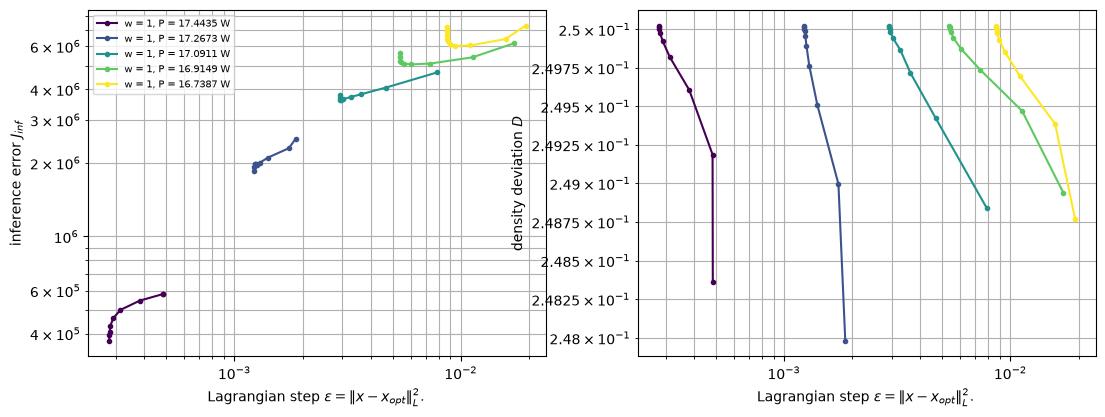

w = 1, P = 17.44351 W: eps_min 2.800e-04, J_inf 3.748e+05, D 2.500e-01, mean density -0.0000, P residual 2.8e-07
  [  0] eps 2.802e-04 (d 2.80e-07): F 2.500e-01, pred 2.500e-01 (err 1.2e-06), cstr res 2.1e-05, |dx|/|x| 3.1e-02, P(x) 1.74435e+01 W, lags [ 0.004 -0.933], 0.25s -> accepted
  step   1: eps 2.802e-04, F 2.500e-01, J_inf 3.939e+05, D 2.500e-01, mean density -0.0000, clipped design 2.7075e-04 W, binary design 0.0000e+00 W | 0 rejected, 0.25s
  [  1] eps 2.811e-04 (d 8.40e-07): F 2.500e-01, pred 2.500e-01 (err 6.5e-06), cstr res 8.2e-05, |dx|/|x| 2.1e-02, P(x) 1.74435e+01 W, lags [ 0.003 -0.539], 0.06s -> accepted
  step   2: eps 2.811e-04, F 2.500e-01, J_inf 4.081e+05, D 2.500e-01, mean density -0.0000, clipped design 2.6942e-04 W, binary design 0.0000e+00 W | 0 rejected, 0.20s
  [  2] eps 2.836e-04 (d 2.52e-06): F 2.500e-01, pred 2.500e-01 (err 1.7e-05), cstr res 5.8e-06, |dx|/|x| 2.0e-02, P(x) 1.74435e+01 W, lags [ 0.001 -0.246], 0.06s -> accepted
  step   3: eps 2.836e-04,

In [85]:
epsFull = lagDist(Vfull)
print(f"dual bound {Pdual:.6e} W, P(Vopt) {evalObj(Vopt):.6e} W, full plate {Pfull:.6e} W")
print(f"L*-distance of the full plate: {epsFull:.3e}, J_inf(Vopt) = {Jref:.3e}, D(Vopt) = {Dfill(Vopt):.3e}")

# sampling presets: coarse | fine
SWEEP = 'coarse'
nP, epsGrow, maxSteps = {'coarse': (5, 3.0, 1000), 'fine': (20, 1.25, 400)}[SWEEP]
print(f"sweep: {SWEEP}, {nP} objective levels, eps growth {epsGrow}, max {maxSteps} steps per level")
Ptargets = np.linspace(Pdual, 0.95*Pdual, nP + 1)[1:]       # from the bound downwards; P = Pdual only admits eps -> 0
epsMax = 1.2*epsFull
stepTol, predTol = 0.05, 0.1
Jtol = 1e-8*Jref           # inference error of a realizable current
Dtol = 1e-4                # mean density within 1e-2 of RHO

# live figure: inference error and density deviation vs Lagrangian step
liveFig, liveAx = plt.subplots(1, 2, figsize=(13, 4.5))
for a_, lab in zip(liveAx, [r'inference error $J_{inf}$', r'density deviation $D$']):
    a_.set_xscale('log'); a_.set_yscale('log'); a_.grid(True, which='both')
    a_.set_xlabel(r'Lagrangian step $\varepsilon = \|x-x_{opt}\|^2_{L^\star}$'); a_.set_ylabel(lab)
liveColors = plt.cm.viridis(np.linspace(0, 1, nP*len(WEIGHTS)))
liveHandle = display(liveFig, display_id=True)
plt.close(liveFig)

def liveUpdate(lines, pts):
    for line, k in zip(lines, (2, 3)):
        line.set_data([p[0] for p in pts], [p[k] for p in pts])
    for a_ in liveAx:
        a_.relim(); a_.autoscale_view()
    if liveHandle is not None:      # None outside Jupyter (batch runs)
        liveHandle.update(liveFig)

def record(eps, x, w):
    # Pareto point: (eps, F, J_inf, D, mean density, clipped design, binary design, x)
    d = np.real(inferredDensity(x))
    return (eps, Ftot(x, w), Jinf(x), Dfill(x), np.real(meanDensity(x)),
            realizedObj(np.clip(d, 0, 1)), realizedObj((d > 0.5).astype(float)), x)

def sweepEps(Ptarget, w, color=None):
    # start on the P level set at the point of minimal Lagrangian distance; it is the
    # expansion point of the first Taylor model and eps_min is the smallest feasible eps
    Ik, epsk, res0 = minEpsPoint(Ptarget)
    pts = [record(epsk, Ik, w)]
    print(f"w = {w:g}, P = {Ptarget:.5f} W: eps_min {epsk:.3e}, J_inf {pts[0][2]:.3e}, D {pts[0][3]:.3e}, "
          f"mean density {pts[0][4]:.4f}, P residual {res0:.1e}", flush=True)
    lines = [a_.plot([], [], 'o-', ms=3, color=color, label=f'w = {w:g}, P = {Ptarget:.4f} W')[0] for a_ in liveAx]
    liveAx[0].legend(fontsize=7); liveUpdate(lines, pts)
    lags, dEps = None, 1e-3*epsk
    nRej, nRejTot, tStep, tLevel = 0, 0, time.time(), time.time()
    for it in range(maxSteps):
        if epsk >= epsMax or dEps < 1e-12*epsMax or (pts[-1][2] < Jtol and pts[-1][3] < Dtol): break
        epsTry = min(epsk + dEps, epsMax)
        # the eps constraint is scaled as L*/eps, so the warm-start multiplier scales with eps
        lagsTry = None if lags is None else lags*np.array([epsTry/epsk, 1.0])
        tTry = time.time()
        I, Fpr, lagsNew, res = inferenceStep(Ik, epsTry, Ptarget, w, lagsTry)
        Fex = Ftot(I, w)
        relStep = np.linalg.norm(I - Ik)/np.linalg.norm(Ik)
        predErr = abs(Fex - Fpr)/abs(Fex)
        ok = res < 1e-4 and relStep < stepTol and predErr <= predTol
        lagStr = "None" if lagsNew is None else np.array2string(np.asarray(lagsNew), precision=3)
        print(f"  [{it:3d}] eps {epsTry:.3e} (d {dEps:.2e}): F {Fex:.3e}, pred {Fpr:.3e} (err {predErr:.1e}), "
              f"cstr res {res:.1e}, |dx|/|x| {relStep:.1e}, P(x) {evalObj(I):.5e} W, lags {lagStr}, "
              f"{time.time()-tTry:.2f}s -> {'accepted' if ok else 'rejected'}", flush=True)
        if ok:
            Ik, epsk, lags = I, epsTry, lagsNew
            pts.append(record(epsk, I, w))
            print(f"  step {len(pts)-1:3d}: eps {epsk:.3e}, F {Fex:.3e}, J_inf {pts[-1][2]:.3e}, D {pts[-1][3]:.3e}, "
                  f"mean density {pts[-1][4]:.4f}, clipped design {pts[-1][5]:.4e} W, binary design {pts[-1][6]:.4e} W | "
                  f"{nRej} rejected, {time.time()-tStep:.2f}s", flush=True)
            nRej, tStep = 0, time.time()
            liveUpdate(lines, pts)
            dEps *= epsGrow
        else:
            dEps *= 0.5; lags = None
            nRej += 1; nRejTot += 1
    print(f"  level done: {len(pts)-1} accepted, {nRejTot} rejected, {time.time()-tLevel:.1f}s", flush=True)
    return pts

t1 = time.time()
front = {}   # (w, P_target) -> list of Pareto points
for iw, w in enumerate(WEIGHTS):
    for i, P in enumerate(Ptargets):
        pts = front[(w, P)] = sweepEps(P, w, liveColors[iw*nP + i])
        e = pts[-1]
        print(f"w = {w:g}, P = {P:.5f} W: {len(pts)} points, eps_end {e[0]:.3e}, J_inf {e[2]:.3e}, D {e[3]:.3e}, "
              f"mean density {e[4]:.4f}, binary {e[6]:.4e} W")
        if e[2] < Jtol and e[3] < Dtol:
            print(f"realizable current with mean density {RHO} found, stopping the sweeps for w = {w:g}")
            break
print(f"time {time.time()-t1:.1f}s")

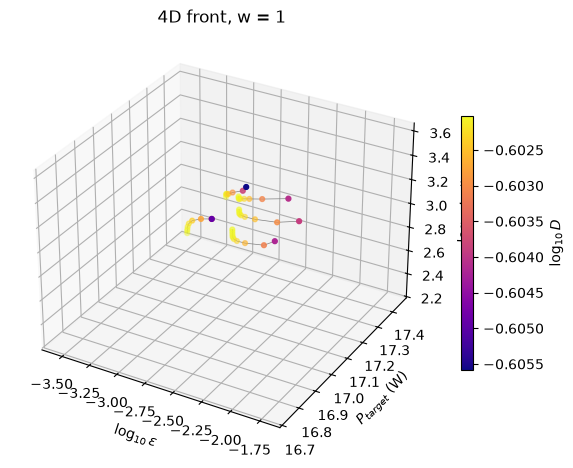

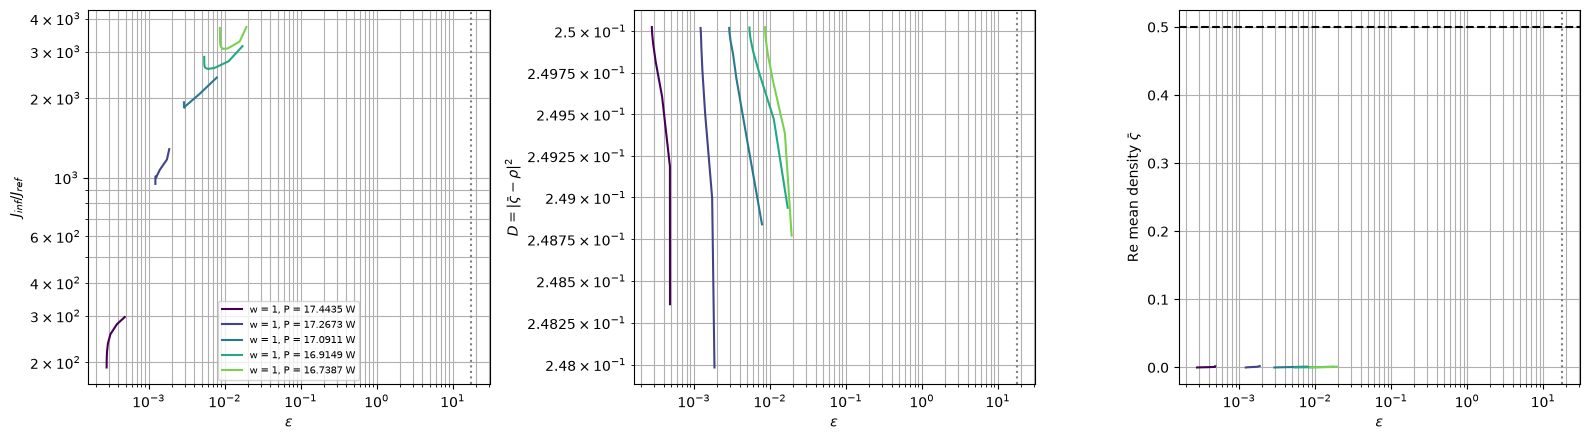

In [86]:
# 4D front: (log eps, P_target, log J_inf) with the density deviation D as colour
allD = np.array([p[3] for pts in front.values() for p in pts])
norm = plt.Normalize(np.log10(allD.min()), np.log10(allD.max()))
fig = plt.figure(figsize=(7*len(WEIGHTS), 5.5))
for iw, w in enumerate(WEIGHTS):
    ax = fig.add_subplot(1, len(WEIGHTS), iw + 1, projection='3d')
    for (ww, P), pts in front.items():
        if ww != w: continue
        e = np.array([p[0] for p in pts]); J = np.array([p[2] for p in pts]); D = np.array([p[3] for p in pts])
        ax.plot(np.log10(e), P*np.ones_like(e), np.log10(J/Jref), '-', c='gray', lw=0.5)
        sc_ = ax.scatter(np.log10(e), P*np.ones_like(e), np.log10(J/Jref), c=np.log10(D), cmap='plasma', norm=norm, s=12)
    ax.set_xlabel(r'$\log_{10}\varepsilon$'); ax.set_ylabel(r'$P_{target}$ (W)'); ax.set_zlabel(r'$\log_{10} J_{inf}/J_{ref}$')
    ax.set_title(f'4D front, w = {w:g}')
fig.colorbar(sc_, ax=fig.axes, shrink=0.6, label=r'$\log_{10} D$')
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
cmap = plt.cm.viridis
for i, ((w, P), pts) in enumerate(front.items()):
    e = np.array([p[0] for p in pts]); col = cmap(i/len(front)); lab = f'w = {w:g}, P = {P:.4f} W'
    axes[0].loglog(e, [p[2]/Jref for p in pts], '-', color=col, label=lab)
    axes[1].loglog(e, [p[3] for p in pts], '-', color=col, label=lab)
    axes[2].semilogx(e, [p[4] for p in pts], '-', color=col, label=lab)
axes[2].axhline(RHO, ls='--', c='k', label=r'target $\rho$')
for a_, lab in zip(axes, [r'$J_{inf}/J_{ref}$', r'$D = |\bar\varsigma - \rho|^2$', r'Re mean density $\bar\varsigma$']):
    a_.axvline(epsFull, ls=':', c='gray'); a_.set_xlabel(r'$\varepsilon$'); a_.set_ylabel(lab); a_.grid(True, which='both')
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

best binary design: 0.000000e+00 W at w = 1, P_target 17.44351 W, eps 2.800e-04, mean density -0.0000 (full plate 4.114174e-02 W)


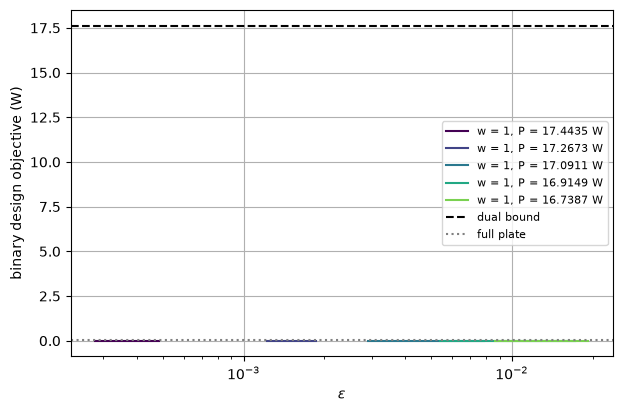

In [87]:
# realized objective of the binary (> 0.5) inferred designs along the front
best = max(((p[6], k, p[0], p[4]) for k, pts in front.items() for p in pts), key=lambda b: b[0])
print(f"best binary design: {best[0]:.6e} W at w = {best[1][0]:g}, P_target {best[1][1]:.5f} W, eps {best[2]:.3e}, "
      f"mean density {best[3]:.4f} (full plate {Pfull:.6e} W)")
fig, ax = plt.subplots(figsize=(7, 4.5))
for i, ((w, P), pts) in enumerate(front.items()):
    ax.semilogx([p[0] for p in pts], [p[6] for p in pts], '-', color=cmap(i/len(front)), label=f'w = {w:g}, P = {P:.4f} W')
ax.axhline(Pdual, ls='--', c='k', label='dual bound'); ax.axhline(Pfull, ls=':', c='gray', label='full plate')
ax.set_xlabel(r'$\varepsilon$'); ax.set_ylabel('binary design objective (W)'); ax.grid(True); ax.legend(fontsize=8)
plt.show()

In [88]:
# save the front: rows (w, P_target, eps, F, J_inf, D, mean density, P_clipped, P_binary)
rows = [(w, P) + p[:7] for (w, P), pts in front.items() for p in pts]
np.savetxt(f'results/quadratic_inference_4D_voltage_front_{SWEEP}.txt', np.array(rows), delimiter=',',
           header='w,P_target,eps,F,J_inf,D,mean_density,P_clipped,P_binary')